In [ ]:
import shap
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import math

In [84]:
splits = joblib.load("splits_cache.pkl")
model = joblib.load("model.pkl")
scaler = joblib.load("scaler.pkl")
selector = joblib.load("selector.pkl")

In [85]:
for split in splits[1:2]:  # only the first split for now
    X_train, y_train, X_val, y_val, X_test, y_test = (
        split["X_train_raw"], split["y_train"],
        split["X_val_raw"],   split["y_val"],
        split["X_test_raw"],  split["y_test"]
    )

    X_train_sel = selector.fit_transform(X_train)
    X_val_sel   = selector.transform(X_val)

    selected_feature_names = selector.get_feature_names_out()
    print("Selected features:", selected_feature_names)

    X_train_scaled = scaler.fit_transform(X_train_sel)
    X_val_scaled   = scaler.transform(X_val_sel)

    X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=selected_feature_names)
    X_val_scaled_df   = pd.DataFrame(X_val_scaled, columns=selected_feature_names)

    model.fit(X_train_scaled_df, y_train)  # ← was missing

    explainer  = shap.LinearExplainer(model, X_train_scaled_df, feature_perturbation="interventional")
    shap_values = explainer(X_val_scaled_df)

c:\Projects\vlr-predictor\.venv\Lib\site-packages\shap\explainers\_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
Background dataset has 593 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=593 when initializing the masker.


Selected features: ['team1_map_duration_sum' 'team1_map_patch_played'
 'team1_map_patch_score_delta_avg' 'team1_map_played'
 'team1_map_score_delta_avg' 'team1_map_score_delta_avg_2'
 'team1_map_score_delta_avg_4' 'team1_map_score_delta_avg_6'
 'team1_map_score_delta_sum' 'team1_map_score_delta_sum_2'
 'team1_map_score_delta_sum_4' 'team1_map_score_delta_sum_6'
 'team1_map_specific_played' 'team1_map_specific_score_delta_avg'
 'team1_map_specific_score_delta_sum' 'team1_map_won_duration_sum'
 'team1_match_best_of_sum' 'team1_match_days_since_last'
 'team1_match_patch_played' 'team1_match_patch_score_delta_avg'
 'team1_match_patch_score_delta_sum' 'team1_match_patch_score_sum'
 'team1_match_played' 'team1_match_score_delta_avg'
 'team1_match_score_delta_avg_2' 'team1_match_score_delta_avg_4'
 'team1_match_score_delta_avg_6' 'team1_match_score_delta_sum'
 'team1_match_score_delta_sum_2' 'team1_match_score_delta_sum_4'
 'team1_match_score_delta_sum_6' 'team1_match_win_streak'
 'team1_play

In [86]:
name_value = zip(selected_feature_names, shap_values.values[0])
name_value = sorted(name_value, key=lambda x: abs(x[1]), reverse=True)

for name, feature_shap in name_value:
    print(f"{name}: {feature_shap}")

team2_map_score_delta_avg: 0.0772400028262333
team2_player_map_stats_specific_three_kills_median_4: 0.06070672058342452
team1_player_map_stats_specific_three_kills_median_4: -0.057282022128620824
team1_match_score_delta_sum_6: -0.05622183660573083
team1_player_map_stats_specific_plants_median_4: -0.051478469206116
team1_match_score_delta_avg: -0.04931754491712146
team2_match_score_delta_avg: 0.0462292945420123
team1_match_score_delta_avg_6: -0.04580841663523171
team1_player_map_stats_specific_assists_median_2: 0.043206767565190575
team1_player_map_stats_specific_two_kills_median_6: -0.04233862369182263
team1_player_map_stats_specific_first_kills_median_6: 0.040305856764608405
team2_map_score_delta_sum_6: 0.03897002450723016
team2_map_score_delta_avg_6: 0.038605734315673934
team1_match_score_delta_sum: -0.03643530815633792
team2_map_score_delta_avg_2: 0.03485100595137339
team2_map_score_delta_sum_2: 0.03485100595137336
team1_map_score_delta_avg: -0.03233538178567632
team2_player_map_sta

<BarContainer object of 5 artists>

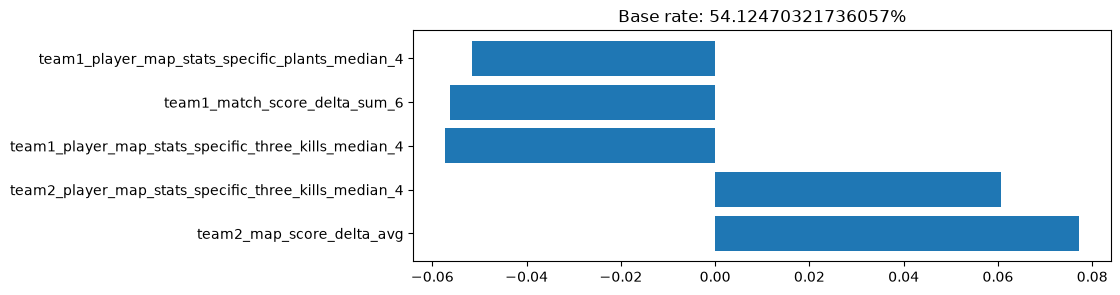

In [ ]:
base_value = (1 / (1 + math.exp(-shap_values.base_values[0]))) * 100
name, value = zip(*name_value[0:5])

plt.figure(figsize=(9,3))
plt.title(f"Base rate: {base_value}%")
plt.barh(name, value)